https://github.com/sihsieh65-tech/cs82a-portfolio/tree/main/Module6

Step 1: Load the CSVs and build the database

In [1]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("store.db")

df_orders = pd.read_csv("store_orders.csv")
df_customers = pd.read_csv("store_customers.csv")

df_orders.to_sql("orders", conn, if_exists="replace", index=False)
df_customers.to_sql("customers", conn, if_exists="replace", index=False)

40

In [2]:
conn

Step 2: First look

In [3]:
pd.read_sql('SELECT * FROM orders LIMIT 5', conn)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [4]:
pd.read_sql('SELECT COUNT(*) FROM orders', conn)

,COUNT(*)
0,200


Step 3: Filter and sort

In [5]:
pd.read_sql('SELECT * FROM orders WHERE amount > 100 ORDER BY amount DESC LIMIT 200', conn)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


Step 4: Aggregate by category

In [6]:
pd.read_sql('SELECT Category, COUNT(*) AS n, AVG(amount) AS avg_amount FROM orders GROUP BY category ORDER BY avg_amount DESC', conn)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


Step 5: Join for spend by city. 

In [7]:
pd.read_sql('SELECT c.city, SUM(o.amount) AS Total FROM customers AS c LEFT JOIN orders AS o ON c.customer_id = o.customer_id GROUP BY c.city ORDER BY Total DESC', conn)

,city,Total
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


Step 6: The row-count audit (markdown cell)

The join table count does not match because there are customers not on the customer list that must have placed orders.Since the customers are placed on the left side of the query the table will only produce order records that match to our customer list. Otherwise the data has not row in the table to "tether" to. In fact, when I checked the csv files in vs code I can see that he customer table has customer ID numbers 1 to 40 while the order table has customer IDs for 900, 901, 902, 903, and 904 accounting for our five missing rows. 

In [8]:
pd.read_sql('SELECT COUNT(*) FROM customers AS c LEFT JOIN orders AS o ON c.customer_id = o.customer_id', conn)

,COUNT(*)
0,195


In [9]:
pd.read_sql('SELECT COUNT(*) FROM customers', conn)

,COUNT(*)
0,40


Step 7: Chart a query result

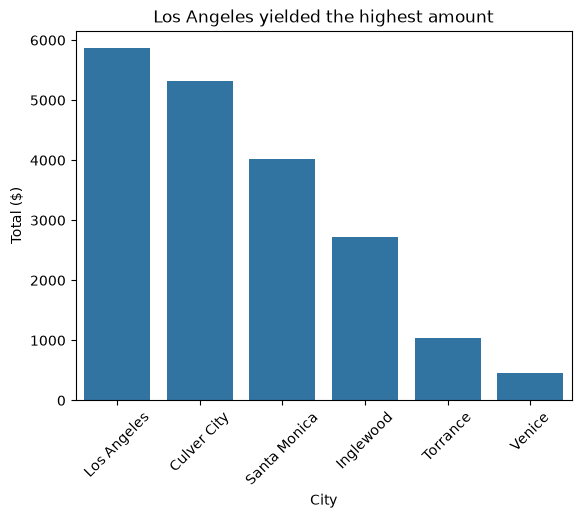

In [10]:
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_sql('SELECT c.city, SUM(o.amount) AS Total FROM customers AS c LEFT JOIN orders AS o ON c.customer_id = o.customer_id GROUP BY c.city ORDER BY Total DESC', conn)
sns.barplot(data=df, x="city", y="Total")
plt.title("Los Angeles yielded the highest amount")
plt.xlabel("City")
plt.xticks(rotation=45)
plt.ylabel("Total ($)")
plt.show()

Step 8: Your own question.

My question is, "what category of merchandise yielded the highest amount in Los Angeles?"

In [11]:
pd.read_sql('SELECT c.city, o.category, SUM(o.amount) AS Total FROM customers AS c LEFT JOIN orders AS o ON c.customer_id = o.customer_id WHERE c.city = "Los Angeles" GROUP BY o.category ORDER BY Total DESC', conn)

,city,category,Total
0,Los Angeles,electronics,3527.42
1,Los Angeles,furniture,1929.67
2,Los Angeles,office,304.96
3,Los Angeles,snacks,100.94


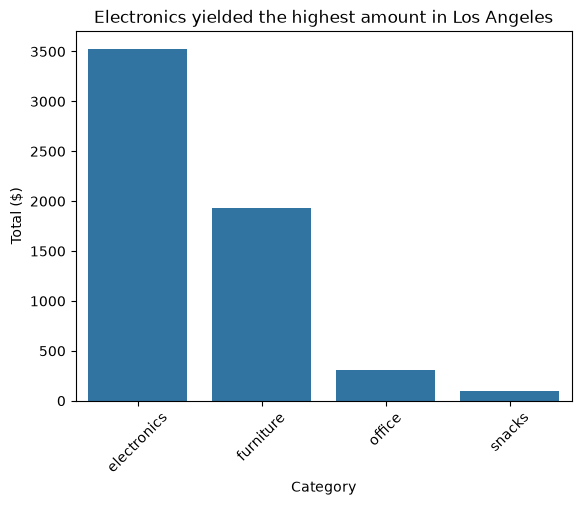

In [12]:
df2 = pd.read_sql('SELECT c.city, o.category, SUM(o.amount) AS Total FROM customers AS c LEFT JOIN orders AS o ON c.customer_id = o.customer_id WHERE c.city = "Los Angeles" GROUP BY o.category ORDER BY Total DESC', conn)
sns.barplot(data=df2, x="category", y="Total")
plt.title("Electronics yielded the highest amount in Los Angeles")
plt.xlabel("Category")
plt.xticks(rotation=45)
plt.ylabel("Total ($)")
plt.show()

In [13]:
conn.close()

Step 9: Ethics note and safe push (markdown cell)

The main thing I would strip or aggregate in the data are the customer names as this represents personally identifying information and should therefore be removed from a public sharing of the results.  